In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import shap

from src.data import load_data, clean_data, split_data
from src.model import build_model, BEST_THRESHOLD

df = clean_data(load_data("../data/telco_churn.csv"))
X_train, X_test, y_train, y_test = split_data(df)

model = build_model(X_train, y_train)
model.fit(X_train, y_train)
test_proba = model.predict_proba(X_test)[:, 1]

c:\projects\churn-prediction\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
prep = model.named_steps["prep"]
clf = model.named_steps["clf"]

X_test_t = prep.transform(X_test)
if hasattr(X_test_t, "toarray"):   # sparse -> normal array, if needed
    X_test_t = X_test_t.toarray()

feature_names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]

explainer = shap.TreeExplainer(clf)
shap_values = explainer.shap_values(X_test_t)
print(shap_values.shape, len(feature_names))

(1409, 45) 45


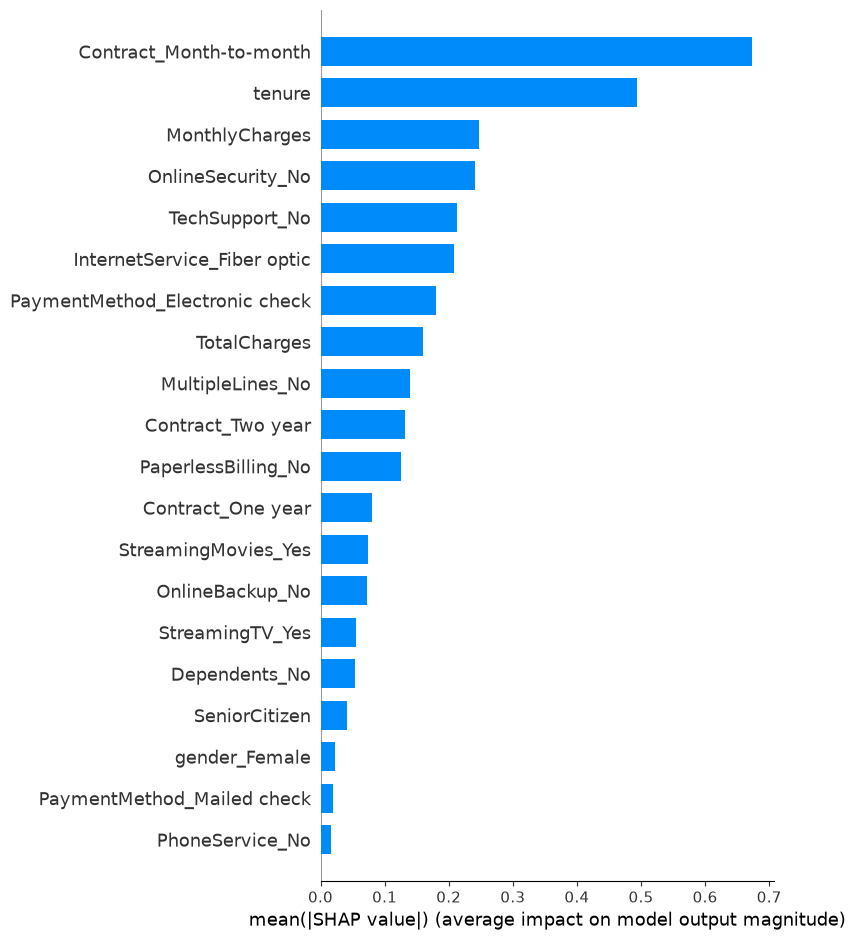

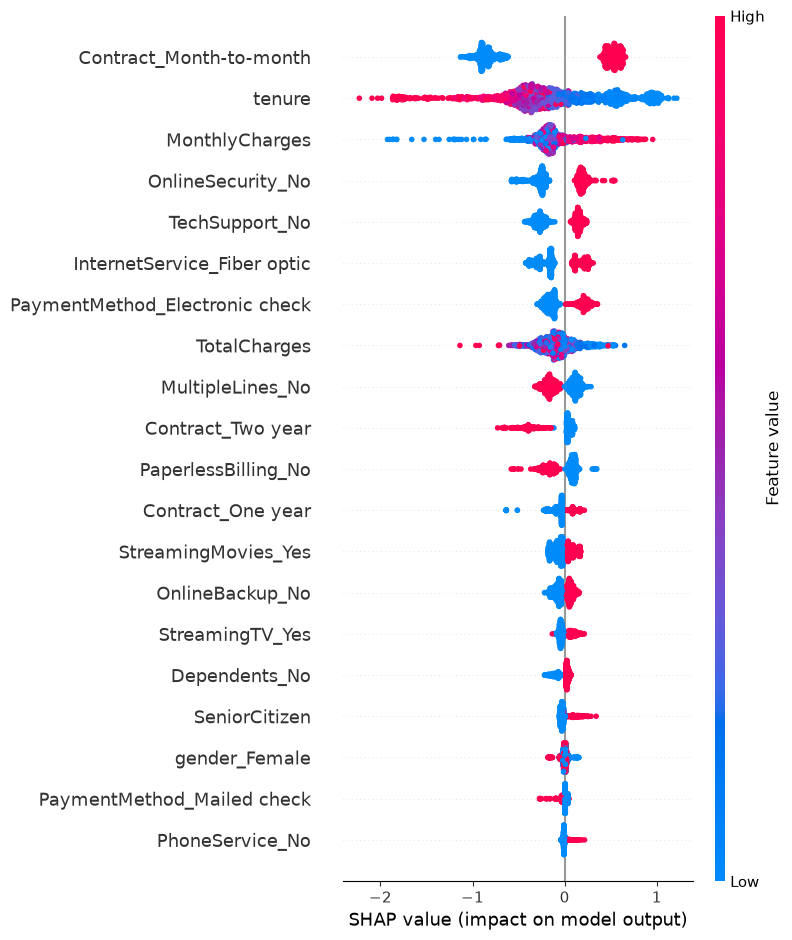

In [3]:
shap.summary_plot(shap_values, X_test_t, feature_names=feature_names, plot_type="bar")
shap.summary_plot(shap_values, X_test_t, feature_names=feature_names)

In [4]:
i = int(np.argmax(test_proba))   # the highest-risk customer in the test set
print("Risk score:", round(test_proba[i], 3), "| actually churned:", y_test.iloc[i])
print(X_test.iloc[i][["Contract", "tenure", "MonthlyCharges", "InternetService", "PaymentMethod"]])

contrib = pd.Series(shap_values[i], index=feature_names)
print(contrib.sort_values(key=abs, ascending=False).head(6).round(2))

Risk score: 0.974 | actually churned: 1
Contract             Month-to-month
tenure                            1
MonthlyCharges                 95.1
InternetService         Fiber optic
PaymentMethod      Electronic check
Name: 3380, dtype: object
tenure                         1.03
Contract_Month-to-month        0.58
MonthlyCharges                 0.28
TechSupport_No                 0.22
InternetService_Fiber optic    0.20
TotalCharges                   0.20
dtype: float32
